In [33]:
import torch
from matplotlib import pyplot

import importlib
import velocity_model
import estimate_velocity
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

L = 5e6
v0 = 1e2
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
h_tgrid = torch.linspace(0, 3600, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
mtrue.v0 = torch.nn.Parameter(torch.tensor([v0], dtype=torch.double))
mtrue.h_log = torch.nn.Parameter(torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double)))
mtrue.g_log = torch.nn.Parameter(torch.log(torch.tensor([10, 0.1], dtype=torch.double)))

coverage = 1e3
x = torch.linspace(0, L, steps=1000)
y_obs = torch.poisson(mtrue.P(x) * coverage)
s_obs = torch.sqrt(y_obs)

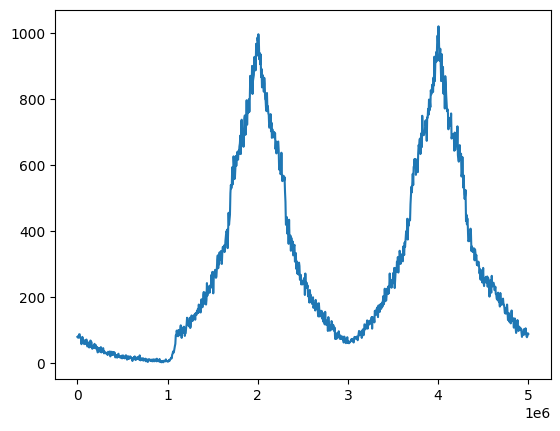

In [34]:
pyplot.plot(x, y_obs.detach().numpy())

In [47]:
m = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
m.h_sigma = 1
m.h_timescale = torch.nn.Parameter(torch.tensor([1e4], dtype=torch.double))
# NOTE: Currently starts with the correct v0
m.v0 = torch.nn.Parameter(torch.tensor([v0], dtype=torch.double))
#m.h_log = torch.nn.Parameter(mtrue.h_log.clone())
#m.g_log = torch.nn.Parameter(mtrue.g_log.clone())

#torch.autograd.set_detect_anomaly(True)
l = velocity_model.VelocityModelLoss(x, y_obs.detach(), s_obs.detach(), m)
fit = estimate_velocity.FitModel(m, l)
fit.optimize()
print(fit.loss())
print(fit.model.penalty())

tensor([468.7737], dtype=torch.float64, grad_fn=<AddBackward0>)
tensor([2.3581], dtype=torch.float64, grad_fn=<MulBackward0>)


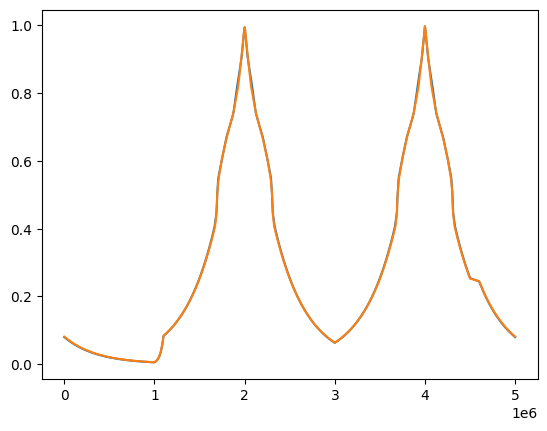

In [48]:
p = m.P(x).detach().numpy()
ptrue = mtrue.P(x).detach().numpy()
pyplot.plot(x, p, label="est")
pyplot.plot(x, ptrue, label="true")

In [53]:
print(fit.model.h_log)
print(fit.model.h_cov_inv())

Parameter containing:
tensor([-0.0596,  0.3324,  0.1104,  0.7621,  0.3293,  0.1385, -1.0801, -1.7874,
        -0.4910, -0.0373, -0.0112], dtype=torch.float64, requires_grad=True)
tensor([[ 1.9987e+00, -1.0006e+00,  1.7511e-05,  1.9256e-05,  2.0931e-05,
          2.2522e-05,  2.4018e-05,  2.5407e-05,  2.6680e-05,  2.7827e-05,
          1.1587e-03],
        [-1.0006e+00,  1.9987e+00, -1.0006e+00,  1.6109e-05,  1.7829e-05,
          1.9482e-05,  2.1055e-05,  2.2536e-05,  2.3915e-05,  2.5181e-05,
          1.1858e-03],
        [ 1.7511e-05, -1.0006e+00,  1.9987e+00, -1.0006e+00,  1.4648e-05,
          1.6346e-05,  1.7980e-05,  1.9539e-05,  2.1010e-05,  2.2382e-05,
          1.2102e-03],
        [ 1.9256e-05,  1.6109e-05, -1.0006e+00,  1.9987e+00, -1.0006e+00,
          1.3135e-05,  1.4814e-05,  1.6433e-05,  1.7980e-05,  1.9444e-05,
          1.2318e-03],
        [ 2.0931e-05,  1.7829e-05,  1.4648e-05, -1.0006e+00,  1.9987e+00,
         -1.0006e+00,  1.1575e-05,  1.3239e-05,  1.4847e-05,  1